In [3]:
# conda env : plot_python

import pandas as pd
import seaborn as sns
import os
import glob
import time
import tqdm
import numpy as np
import pybedtools


# Plotting
from adjustText import adjust_text
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

# saving folder
figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/DMR_inspection/"
os.makedirs(figureDir, exist_ok=True)

dr=f"/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/missing_iDMRs"
os.chdir(dr)

In [98]:
x_order = [   'chr1_11044370_11044544',    'chr1_21120031_21120143',
  'chr1_227504793_227504903',   'chr10_13172944_13173273',
   'chr10_98458604_98458947',     'chr12_3845430_3845920',
     'chr12_6454803_6455271',   'chr12_14651159_14651402',
   'chr12_96198127_96198449', 'chr12_130374845_130375163',
   'chr13_19317211_19317685',   'chr13_98425642_98426046',
 'chr13_100190731_100191002', 'chr14_100719510_100719614',
   'chr15_21563910_21564305',   'chr15_21674147_21675281',
   'chr15_21763297_21763709',   'chr15_21890432_21891180',
   'chr15_21897209_21897954',   'chr15_22312618_22313135',
   'chr15_27466585_27466749',   'chr15_78982358_78982976',
     'chr16_3322511_3322654',   'chr19_39096790_39096912',
    'chr2_39252404_39252862',  'chr2_130015734_130016047',
  'chr2_132265092_132265797',   'chr20_65030021_65030481',
   'chr20_65758266_65759319',   'chr21_12407958_12408119',
   'chr21_45047466_45048210',   'chr22_21798922_21799586',
  'chr4_158113274_158113803',        'chr5_561353_562753',
  'chr5_111236976_111237741',  'chr5_117967773_117967929',
  'chr5_138415651_138415958',    'chr6_29555331_29556045',
    'chr6_31425008_31425410',  'chr6_160184517_160185088',
  'chr6_169727799_169727970',    'chr7_65134148_65134309',
    'chr8_39591596_39591695',    'chr9_41939693_41940117',
  'chr9_104264526_104264928',  'chr9_109746840_109747389',
  'chr9_125287844_125289117',  'chr9_134423466_134424180']

In [99]:
met = pd.read_csv("missing_idmrs.methylation.bed",
                  sep = '\t', header = None, names = ['chr','start','end','ncpg','total','meth','sample','hap'])
met['id'] = met['chr'] + "_" + met['start'].astype(str) + "_" + met['end'].astype(str)
met['cov'] = met['total'] / met['ncpg']
met.head(2)

,chr,start,end,ncpg,total,meth,sample,hap,id,cov
0,chr1,11044370,11044544,19,754,206,HG002,1,chr1_11044370_11044544,39.684211
1,chr1,21120031,21120143,5,156,4,HG002,1,chr1_21120031_21120143,31.200000


In [100]:
missing_df_5e2 = pd.read_csv("/path/to/project/pooch/findings/missing_iDMRs/missing_idmrs.p5e2.bed",
                          sep = '\t' ,header = None, names = ['chr','start','end'])
missing_df_5e2['id'] = missing_df_5e2['chr'] + "_" + missing_df_5e2['start'].astype(str) + "_" + missing_df_5e2['end'].astype(str)
missing_df_5e2['p'] = "5e2"

print(f"line num : {missing_df_5e2.shape[0]}")
missing_df_5e2.head(2)



line num : 39


,chr,start,end,id,p
0,chr1,11044370,11044544,chr1_11044370_11044544,5e2
1,chr1,21120031,21120143,chr1_21120031_21120143,5e2


In [101]:
missing_df = pd.read_csv("/path/to/project/pooch/findings/missing_iDMRs/missing_idmrs.bed",
                          sep = '\t' ,header = None, names = ['chr','start','end'])
missing_df['id'] = missing_df['chr'] + "_" + missing_df['start'].astype(str) + "_" + missing_df['end'].astype(str)
missing_df['p'] = "1e3"
print(f"line num : {missing_df.shape[0]}")
missing_df.head(2)

line num : 48


,chr,start,end,id,p
0,chr1,11044370,11044544,chr1_11044370_11044544,1e3
1,chr1,21120031,21120143,chr1_21120031_21120143,1e3


In [102]:
missing_bed = pd.merge(missing_df_5e2,missing_df , on = 'id', how = "right")

print(f"line num : {missing_bed.shape[0]}")
missing_bed['p_x'] = missing_bed['p_x'].fillna("found")
missing_bed.head(2)


line num : 48


,chr_x,start_x,end_x,id,p_x,chr_y,start_y,end_y,p_y
0,chr1,11044370.0,11044544.0,chr1_11044370_11044544,5e2,chr1,11044370,11044544,1e3
1,chr1,21120031.0,21120143.0,chr1_21120031_21120143,5e2,chr1,21120031,21120143,1e3


In [103]:
missing_bed.groupby('p_x').size()

p_x
5e2      39
found     9
dtype: int64

In [104]:
list(missing_bed.loc[missing_bed['p_x'] == "found", 'id'])

['chr13_100190731_100191002',
 'chr15_21563910_21564305',
 'chr15_21763297_21763709',
 'chr15_21897209_21897954',
 'chr15_22312618_22313135',
 'chr15_78982358_78982976',
 'chr16_3322511_3322654',
 'chr2_39252404_39252862',
 'chr20_65030021_65030481']

In [105]:
na_bed = pybedtools.BedTool("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/dmls.N05_filt.all_chr.NA.bed.gz")
missing_bed = pybedtools.BedTool.from_dataframe(missing_df)
intersect = missing_bed.intersect(na_bed, loj=True)
intersect_df_missing_na = intersect.to_dataframe(header=None, names=missing_df.columns.to_list() + ['chr_na','start_na','end_na'])
intersect_df_missing_na['id'] = intersect_df_missing_na['chr'] + "_" + intersect_df_missing_na['start'].astype(str) + "_" + intersect_df_missing_na['end'].astype(str)
intersect_df_missing_na = intersect_df_missing_na.groupby('id').agg(na_count = ('chr_na', 'count')).reset_index()
intersect_df_missing_na.head(2)

,id,na_count
0,chr10_13172944_13173273,1
1,chr10_98458604_98458947,1


/tmp/ipykernel_1775065/146545589.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


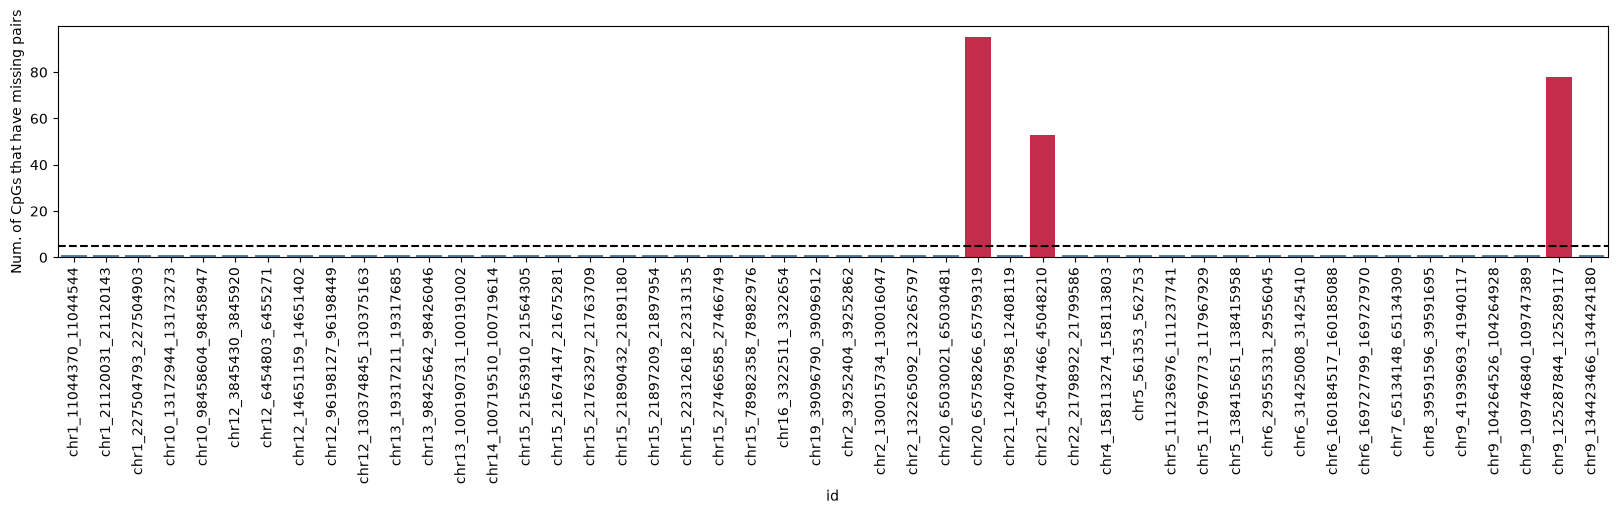

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Align the data with your custom x_order to map colors accurately
ordered_df = (
    intersect_df_missing_na.set_index("id").reindex(x_order).reset_index()
)

# 2. Define colors based on the threshold condition (> 5)
# (e.g., 'crimson' if above 5, 'steelblue' otherwise)
bar_colors = [
    "crimson" if val > 5 else "steelblue" for val in ordered_df["na_count"]
]

# 3. Plot the chart
plt.figure(figsize=(20, 3))
sns.barplot(
    data=ordered_df,
    x="id",
    y="na_count",
    order=x_order,
    palette=bar_colors,
)

plt.xticks(rotation=90)
plt.ylabel("Num. of CpGs that have missing pairs")
plt.axhline(5, color="black", linestyle="--", linewidth=1.5)  # Reference line at 5
plt.show()


In [107]:
summary_df = met.groupby('id').agg(ncpg_num=('ncpg', 'mean'),
                      cov_meen = ('cov','mean')).reset_index()
summary_df = pd.merge(summary_df, intersect_df_missing_na, on = 'id')
summary_df['ncpg_num_wo_na'] = summary_df['ncpg_num'] - summary_df['na_count']
summary_df.head(2)

,id,ncpg_num,cov_meen,na_count,ncpg_num_wo_na
0,chr10_13172944_13173273,25.979675,35.083472,1,24.979675
1,chr10_98458604_98458947,17.959350,29.590799,1,16.959350


/tmp/ipykernel_1775065/1101683730.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


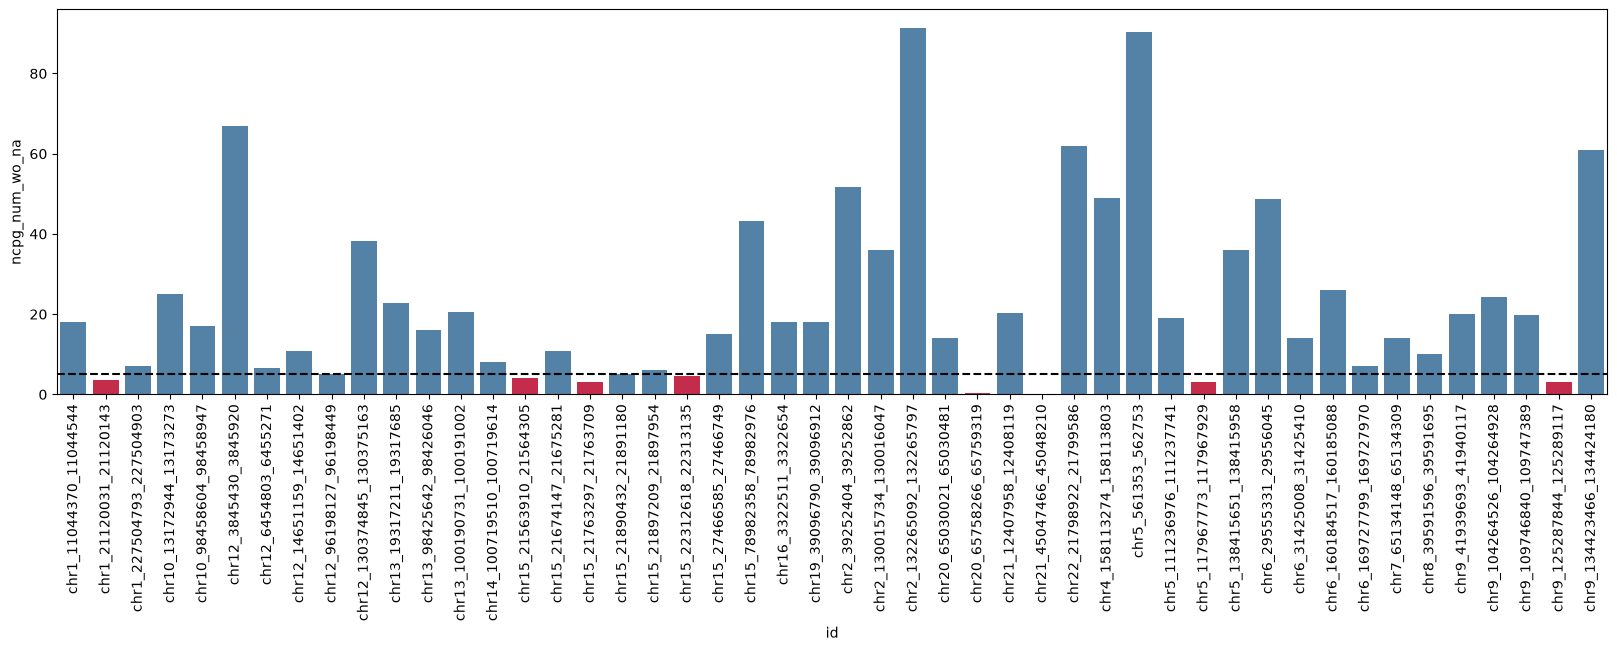

In [108]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Align the data with your custom x_order to map colors accurately
ordered_df = summary_df.set_index("id").reindex(x_order).reset_index()

# 2. Define colors based on the threshold condition (< 5)
# (e.g., 'crimson' if less than 5, 'steelblue' otherwise)
bar_colors = [
    "crimson" if val < 5 else "steelblue" for val in ordered_df["ncpg_num_wo_na"]
]

# 3. Plot the chart
plt.figure(figsize=(20, 5))
sns.barplot(
    data=ordered_df,
    x="id",
    y="ncpg_num_wo_na",
    order=x_order,
    palette=bar_colors,
)

plt.xticks(rotation=90)
plt.axhline(5, color="black", linestyle="--", linewidth=1.5)
plt.show()


([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47],
 [Text(0, 0, 'chr1_11044370_11044544'),
  Text(1, 0, 'chr1_21120031_21120143'),
  Text(2, 0, 'chr1_227504793_227504903'),
  Text(3, 0, 'chr10_13172944_13173273'),
  Text(4, 0, 'chr10_98458604_98458947'),
  Text(5, 0, 'chr12_3845430_3845920'),
  Text(6, 0, 'chr12_6454803_6455271'),
  Text(7, 0, 'chr12_14651159_14651402'),
  Text(8, 0, 'chr12_96198127_96198449'),
  Text(9, 0, 'chr12_130374845_130375163'),
  Text(10, 0, 'chr13_19317211_19317685'),
  Text(11, 0, 'chr13_98425642_98426046'),
  Text(12, 0, 'chr13_100190731_100191002'),
  Text(13, 0, 'chr15_21563910_21564305'),
  Text(14, 0, 'chr15_21674147_21675281'),
  Text(15, 0, 'chr15_21763297_21763709'),
  Text(16, 0, 'chr15_21890432_21891180'),
  Text(17, 0, 'chr

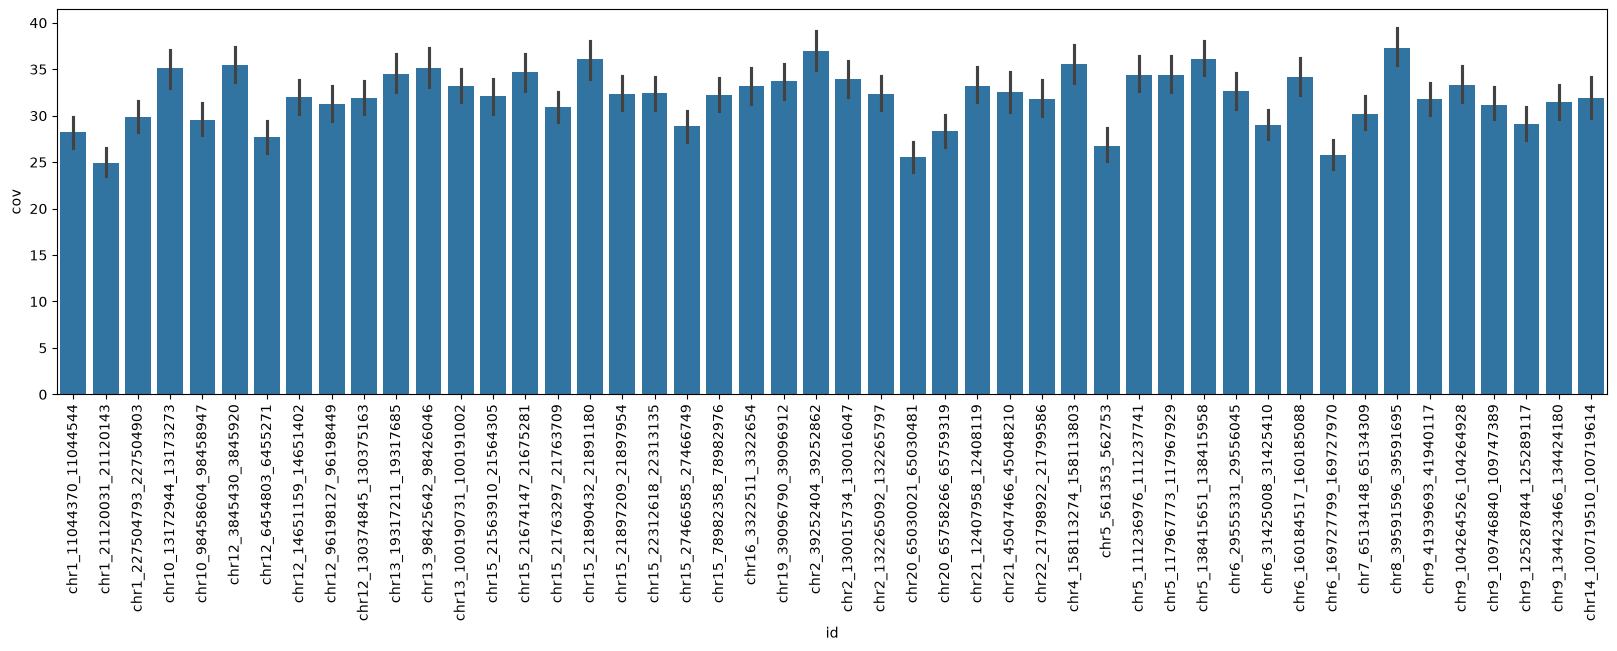

In [109]:
plt.figure(figsize=(20,5))
sns.barplot(met, x = "id", y ="cov")
plt.xticks(rotation = 90)

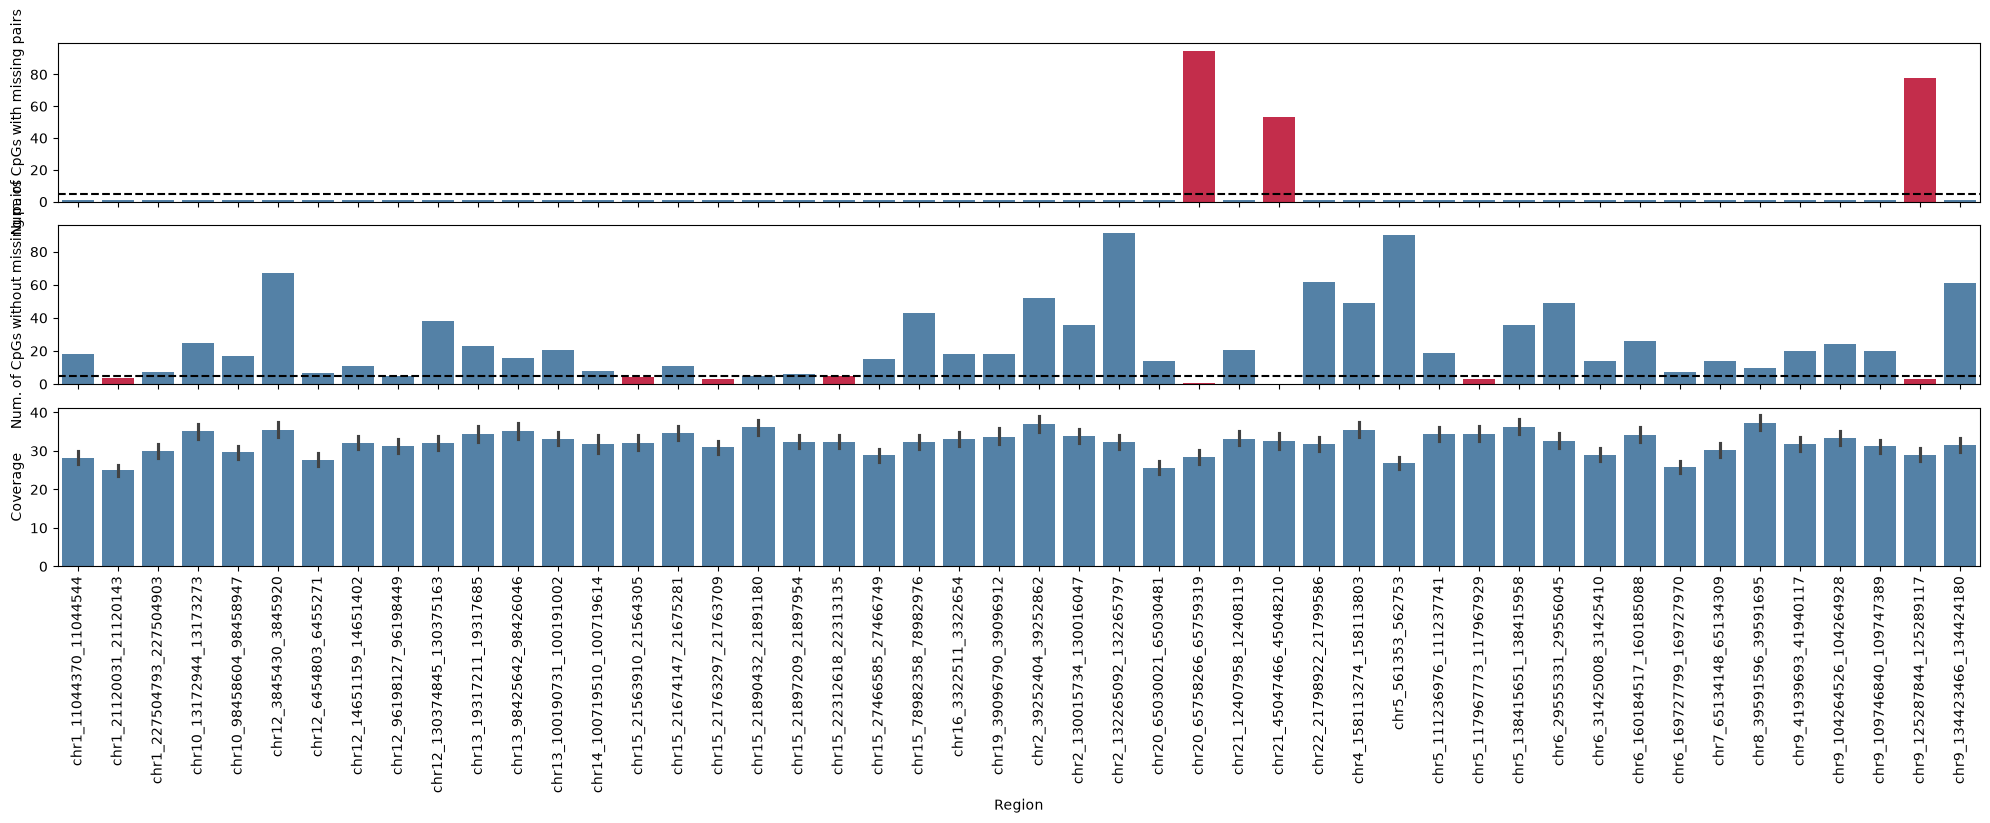

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(20, 8),
    sharex=True,
)

# 1. Missing pairs
ordered_missing = (
    intersect_df_missing_na.set_index("id").reindex(x_order).reset_index()
)
missing_colors = {
    row["id"]: "crimson" if row["na_count"] > 5 else "steelblue"
    for _, row in ordered_missing.iterrows()
}

sns.barplot(
    data=ordered_missing,
    x="id",
    y="na_count",
    order=x_order,
    hue="id",
    palette=missing_colors,
    dodge=False,
    legend=False,
    ax=axes[0],
)
axes[0].axhline(5, color="black", linestyle="--", linewidth=1.5)
axes[0].set_ylabel("Num. of CpGs with missing pairs")

# 2. CpGs without missing pairs
ordered_summary = summary_df.set_index("id").reindex(x_order).reset_index()
cpg_colors = {
    row["id"]: "crimson" if row["ncpg_num_wo_na"] < 5 else "steelblue"
    for _, row in ordered_summary.iterrows()
}

sns.barplot(
    data=ordered_summary,
    x="id",
    y="ncpg_num_wo_na",
    order=x_order,
    hue="id",
    palette=cpg_colors,
    dodge=False,
    legend=False,
    ax=axes[1],
)
axes[1].axhline(5, color="black", linestyle="--", linewidth=1.5)
axes[1].set_ylabel("Num. of CpGs without missing pairs")

# 3. Coverage
sns.barplot(
    data=met,
    x="id",
    y="cov",
    order=x_order,
    color="steelblue",
    ax=axes[2],
)
axes[2].set_ylabel("Coverage")

for ax in axes:
    ax.set_xlabel("")

axes[2].set_xlabel("Region")
axes[2].tick_params(axis="x", labelrotation=90)

plt.savefig(f"{figureDir}/missing_idmrs_detail.pdf")
plt.tight_layout()
plt.show()